### **Maestría en Inteligencia Artificial Aplicada**

###**Curso: Inteligencia Artificial y Aprendizaje Automático**

**Tecnológico de Monterrey**

Prof Luis Eduardo Falcón Morales

### **Actividad de la Semana: Problema de Clasificación con Datos Desbalanceados : Oil-Spill**

* **Nombre:** Mariana Pérez Sánchez

* **Matrícula:** A01099907

# **Introducción**

* La actividad se basa en los datos conocidos como "oil-spill" (derrame de petróleo).

* En la web puedes encontrar varias referencias a este mismo problema, pero en donde el archivo de datos no es exactamente igual. Por ello y para asegurar que el conjunto de datos con el que estaremos trabajando es el mismo para todos, dicho archivo lo encontrarás en Canvas.

* El archivo con los datos de esta actividad lo encuentras en Canvas con el nombre "oil-spill.csv".

* En la siguiente liga se encuentra el artículo original relacionado a dicha base de datos:

https://webdocs.cs.ualberta.ca/~holte/Publications/oilspill.pdf

* De dicho artículo sabemos que los datos incluyen 50 columnas y 937 registros. Las primeras 49 columnas son métricas obtenidas de imágenes satelitales del océano, en algunas de las cuales se tiene petróleo que fue derramado por alguna fuente desconocida. En el artículo se describe a detalle la manera en que se obtuvieron dichas columnas. Para la presente actividad es suficiente con saber que dichos valores numéricos son información valiosa que nos permiten entender lo qu hay en la imagen, en particular, el ayudar a distinguir si hay o no derramamiento de combustible en dicha imagen.

* La última columna llamada "target" puede tomar el valor de 1 (hay derrame en ese pedazo de la imagen) o 0 (no hay derrame en ese pedazo de la imagen).

* Así, por el momento es suficiente con que consideres que cada una de las primeras 49 columnas son variables de tipo numérico continua y la última es de valor binario, en este problema de clasificación.

* En un curso posterior de visión computacional dentro de la maestría podrás estudiar técnicas para extraer dicha información numérica de las imágenes, en caso de que este tema sea de tu interés.

* Para fines de esta actividad usaremos la librería llamada "imbalanced-learn", usada comunmente en problemas de clases desbalanceadas. En particular, usaremos el siguiente método que nos proporciona un reporte con los valores de varias métricas utilizadas comunmente en problemas de clases desbalanceadas:

https://imbalanced-learn.org/stable/references/generated/imblearn.metrics.classification_report_imbalanced.html

In [1]:
# Incluye a continuación todas librerías que consideres necesarias:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix
from sklearn.metrics import recall_score, precision_score, f1_score






In [3]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


**NOTAS:**

* **Para fines de esta actividad, pre-procesaremos los datos de manera genérica para poder concentrarnos en los temas relacionados al curso.**

* **Siempre podrás regresar en el futuro y trabajar de mejor manera el pre-procesamiento de los datos.**

In [5]:
# Cargamos los datos del archivo de la actividad:
path = '/content/drive/MyDrive/Maestría/Inteligencia artificial y aprendizaje automático/Actividad semana 4/oil_spill.csv'
df = pd.read_csv(path)

# Eliminamos las siguientes columnas:
#   - f_1 contiene información de secciones (batches) de las imágenes que no requerimos para esta actividad.
#   - f_23 tiene un solo valor constante.
df.drop("f_1", axis=1, inplace=True)
df.drop("f_23", axis=1, inplace=True)

# Despleguemos los primeros valores:
print('Dimensión del DataFrame',df.shape)
df.head(4).T


Dimensión del DataFrame (937, 48)


,0,1,2,3
f_2,2558.00,22325.00,115.00,1201.00
f_3,1506.09,79.11,1449.85,1562.53
f_4,456.63,841.03,608.43,295.65
f_5,90.00,180.00,88.00,66.00
f_6,6395000.00,55812500.00,287500.00,3002500.00
f_7,40.88,51.11,40.42,42.40
f_8,7.89,1.21,7.34,7.97
f_9,29780.00,61900.00,3340.00,18030.00
f_10,0.19,0.02,0.18,0.19
f_11,214.70,901.70,86.10,166.50


In [6]:
# Particionamos los datos de entrada (X) y de salida (y):
X,y = df.iloc[:,:-1], df.iloc[:,-1]

# Utilizamos las semillas indicadas para la reproducibilidad de los resultados de la actividad:
Xtv, Xtest, ytv, ytest = train_test_split(X, y, test_size=0.12, stratify=y, shuffle=True, random_state=1)
Xtrain, Xval, ytrain, yval = train_test_split(Xtv, ytv, test_size=0.2, shuffle=True, random_state=7)


# Veamos que tenemos un problema de clases bastante desbalanceadas.
# Para ello mostremos la distribución de los conjuntos de entrenamiento, validación y prueba.
# En realidad, solo deberíamos mostrar los valores del conjunto de entrenamiento
# para evitar el problema del filtrado de información (data leakage). Sin embargo,
# con fines meramente euducativos, mostramos también la distribución de los conjuntos
# de validación (val) y de prueba (test), para darnos una idea de la complejidad del
# problema y del reto que tenemos para entrenar un buen modelo de clasificación.
# Es decir, tenemos una cantidad muy pequeña de datos de la clase positiva
# en el conjunto de validación y en el de prueba y aún así, deberemos
# hacer el esfuerzo para diseñar un buen modelo que distinga estos pocos datos.

print('\nPartición de los conjuntos de Entrenamiento, Validación y Prueba:')
print('+'*70)
tmp = 100 * (ytrain.sum() / len(ytrain))
print('Train:')
print('Conteo_clase_positiva= %d (%.2f%%)' % (ytrain.sum(), tmp))
print('Conteo_clase_negativa= %d (%.2f%%)' % ((len(ytrain)-ytrain.sum()), 100-tmp))

print('\nValidation:')
tmp = 100 * (yval.sum() / len(yval))
print('Conteo_clase_positiva= %d (%.2f%%)' % (yval.sum(), tmp))
print('Conteo_clase_negativa= %d (%.2f%%)' % ((len(yval)-yval.sum()), 100-tmp))

print('\nTest:')
tmp = 100 * (ytest.sum() / len(ytest))
print('Conteo_clase_positiva= %d (%.2f%%)' % (ytest.sum(), tmp))
print('Conteo_clase_negativa= %d (%.2f%%)' % ((len(ytest)-ytest.sum()), 100-tmp))


Partición de los conjuntos de Entrenamiento, Validación y Prueba:
++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++
Train:
Conteo_clase_positiva= 28 (4.25%)
Conteo_clase_negativa= 631 (95.75%)

Validation:
Conteo_clase_positiva= 8 (4.85%)
Conteo_clase_negativa= 157 (95.15%)

Test:
Conteo_clase_positiva= 5 (4.42%)
Conteo_clase_negativa= 108 (95.58%)


# **Ejercicio-1**

### **Consideremos en primer instancia que los errores de falsos poitivos y falsos negativos son igualmente costosos. Y ya que tenemos un problema bastante desbalanceado, usaremos la media geométrica como métrica principal para buscar el mejor modelo. A partir de esta información, responde las siguientes preguntas:**

* ### **a) En el contexto de este problema del derrame de petróleo, ¿cómo justificas el no utilizar la métrica de la exactitud (accuracy), y sí utlizar la métrica G_mean?**

* ### **b) En el contexto del problema ¿qué significa un Falso Positivo y cuáles podrían ser algunas de sus implicaciones al cometer uno de estos errores?**

* ### **c) En el contexto del problema ¿qué significa un Falso Negativo y cuáles podrían ser algunas de sus implicaciones al cometer uno de estos errores?**





Respuestas Ejercicio-1:

### +++++++++++ Inicia sección para agregar texto ++++++++++++++++

* 1a) El usar únicamente acuraccy podría llevarnos a una interpretación incorrecta del desempeño del modelo. Al tener clases desbalanceadas, en este caso teniendo 95.6% correspondiente a la clase mayoritaria, podríamos tener un accuracy elevado incluso si el modelo no detecta los derrames correctamente. G-mean permite evaluar la sensibilidad (recall) y especificidad del modelo, considerando su capacidad para clasificar correctamente ambas clases. Se puede ver si el modelo tiene un desempeño equilibrado entre ambas clases.

* 1b) Predecir un derrame cuando no lo hay podría generar un impacto económico y operativo, ya que se podrían destinar recursos innecsarios para atender un supuesto derrame, como personal espcializado, equipos de inspección y acciones de contención. Representaría costos adicionales o uso ineficiente de los recursos.

* 1c) Considero que este error tien un mayor impacto, aunque se establece que el no predecir un derrame tiene el mismo impacto económico que un Falso Positivo, al no predecir correctamente cuando sí existe un derrame, podría llevar a no poder contenerlo a tiempo y que el daño ambiental sea irreparable.

### +++++++++++ Termina sección para agregar texto ++++++++++++++

* **Incluyamos a continuación una breve descripción numérica y gráfica del conjunto de entrenamiento. Es lo mínimo en cuanto a pre-procesamiento que haremos. Más adelante puedes regresar y realizar un mayor análisis.**

* **En dado caso, puedes incluir más celdas con análisis adicionales, si así lo deseas.**

In [7]:
Xtrain.describe().T

,count,mean,std,min,25%,50%,75%,max
f_2,659.0,350.377845,1.911459e+03,10.00,19.000,63.00,134.000,28526.00
f_3,659.0,692.040516,6.013521e+02,1.92,83.905,646.26,1229.325,1789.13
f_4,659.0,853.822398,5.259526e+02,1.00,435.500,719.81,1238.040,2724.57
f_5,659.0,85.613050,4.564260e+01,0.00,54.000,74.00,120.500,180.00
f_6,659.0,831366.966616,4.158159e+06,71718.00,125000.000,185000.00,337500.000,71315000.00
f_7,659.0,43.517132,1.287405e+01,21.24,33.760,40.35,53.090,82.64
f_8,659.0,9.244294,3.590490e+00,1.21,6.935,8.33,11.045,23.47
f_9,659.0,4094.624431,8.960913e+03,704.00,1332.000,2100.00,3445.000,160740.00
f_10,659.0,0.221730,8.687786e-02,0.02,0.170,0.21,0.260,0.67
f_11,659.0,110.794537,6.187135e+01,41.00,84.400,100.10,116.300,901.70


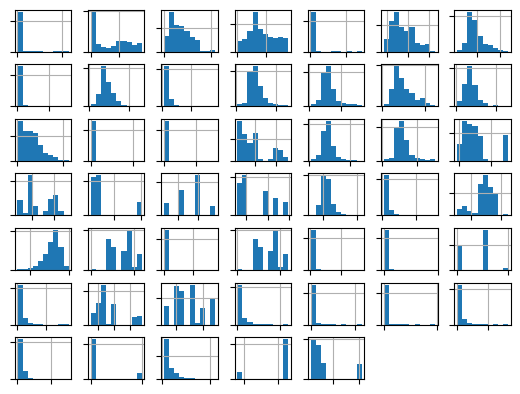

In [8]:
# Histogramas:
ax = Xtrain.hist()
# Quitemos toda la información del gráfico para visualizarlos de manera sencilla:
for axis in ax.flatten():
  axis.set_title('')
  axis.set_xticklabels([])
  axis.set_yticklabels([])
plt.show()



In [9]:
Xtrain.info()

<class 'pandas.core.frame.DataFrame'>
Index: 659 entries, 433 to 625
Data columns (total 47 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   f_2     659 non-null    int64  
 1   f_3     659 non-null    float64
 2   f_4     659 non-null    float64
 3   f_5     659 non-null    int64  
 4   f_6     659 non-null    float64
 5   f_7     659 non-null    float64
 6   f_8     659 non-null    float64
 7   f_9     659 non-null    float64
 8   f_10    659 non-null    float64
 9   f_11    659 non-null    float64
 10  f_12    659 non-null    float64
 11  f_13    659 non-null    float64
 12  f_14    659 non-null    float64
 13  f_15    659 non-null    float64
 14  f_16    659 non-null    float64
 15  f_17    659 non-null    float64
 16  f_18    659 non-null    float64
 17  f_19    659 non-null    float64
 18  f_20    659 non-null    float64
 19  f_21    659 non-null    float64
 20  f_22    659 non-null    float64
 21  f_24    659 non-null    float64
 22  f_25 

**En resumen:**

* De lo anterior observamos que:
  * Todos los valores ya son numéricos, positivos, negativos o cero.
  * No hay datos perdidios.
  * La diferencia de escala entre todos los factores es muy diversa y la distribución de las variables también es muy variada.

* **Como una primera aproximación transformaremos todos los factores con la Yeo-Johnson para corregir un poco el sesgo de las distribuciones que suele afectar en general a los modelos como la regresión logística y luego los escalaremos para ayudar a que todos los factores estén en iguales condiciones de mostrar su importancia.**

# **Ejercicio-2**

### **En relación a la transformación Yeo-Johnson, investiga:**

* ### **a) ¿En qué consiste dicha transformación?**

* ### **b) ¿Cuál es su diferencia con la transformación Box-Cox?**


Respuestas Ejercicio-2:

### +++++++++++ Inicia sección para agregar texto ++++++++++++++++

* 2a) Yeo-Johnson es una técnica matemática que busca reducir la asimetría de los datos y apeoximar su distribución a una distribución normal. En este caso, considero importante aplicarla porque al analizar los histogramas podemos observar que las variables presentan diferentes distribuciones y variación en la asimetría.
Una de sus principales características es que permite trabjar con valores positivos, negativos y cero.

* 2b) Box-cox también es una técnica matemática que busca reducir la asimetría de los datos y aproximar su distribución a una distribuciónn normal, sin embargo se requiere trabajar únicamente con valores positivos.



### +++++++++++ Termina sección para agregar texto ++++++++++++++

In [11]:
# Transformaciones numéricas evitando el filtrado de información:

from sklearn.preprocessing import MinMaxScaler, PowerTransformer, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

numericas_pipeline = Pipeline(steps = [('impMediana', SimpleImputer(strategy='mean')),
                                       ('yeo-johnson', PowerTransformer(method='yeo-johnson')),
                                       ('std_transformer', StandardScaler()),
                                       ])

numericas_pipeline_nombres = Xtrain.columns

columnasTransformer = ColumnTransformer(transformers = [('num', numericas_pipeline, numericas_pipeline_nombres)],
                                        remainder='passthrough')

# **Ejercicio-3**

### **En este ejercicio deberás obtener el valor de umbral del modelo base (baseline) con el conjunto de entrenamiento, que nos ayude a determinar si un modelo está subentrenado.**

* ### **a) Encuentra la estrategia (strategy) del DummyClassifier más adecuada. Además, selecciona el número de divisiones (n_splits) de RepeatedStratifiedKFold que consideres sea el más adecuado para particionar en los conjuntos de entrenamiento y validación al aplicar validación cruzada con el modelo DummyClassifier. Prueba varios valores y observa el resultado de la media y desviación estándar antes de hacer tu mejor selección. Responde a continuación cómo llegaste a decidirte por valor que seleccionaste.**

* ### **b) Con base a tu mejor decisión para "strategy" y "n_splits", ¿cuál es el valor que se usará para determinar si un modelo está subentrenado, al usar la métrica G_mean?**

* ### **c) Si utilizáramos la métrica de la exactitud (accuracy) en este problema del derrame del petróleo, ¿cuál sería el valor de umbral del modelo base a superar? Incluye además la matriz de confusión de este modelo ingenuo con la métrica de la exactitud.**

Respuestas Ejercicio-3:

### +++++++++++ Inicia sección para agregar texto ++++++++++++++++


* 3a) La estrategia seleccionada es "uniform" ya que obtuvimos un G-mean mayor que las otras dos estrategias. Se usó un n_split = 5 ya que al dividir los datos, podemos mantener la proporción entre las clases en cada subdivisión.

* 3b) Se usará el valor = 50.8%

* 3c) El valor sería 95.7%



### +++++++++++ Termina sección para agregar texto ++++++++++++++

NOTA: Recuerda revisar la documentación correspondiente de sklearn para la selección adecuada de los argumentos:

* DummyClassifier:

https://scikit-learn.org/stable/modules/generated/sklearn.dummy.DummyClassifier.html

* RepeatedStratifiedKFold:

https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.RepeatedStratifiedKFold.html

In [13]:
# Definamos una variable con la métrica G-mean a utilizar en los modelos:
from sklearn.metrics import make_scorer
from imblearn.metrics import geometric_mean_score

mi_metrica = make_scorer(geometric_mean_score)

In [15]:
# Utilicemos la función DummyClassifier de sklearn con la métrica G-mean para
# obtener el desempeño del modelo base (baseline).

# Usa esta celda para probar diferentes valores de "strategy" y "n_splits".
# Con base a los resultados observados selecciona tus mejores opciones y
# responde a las preguntas de los incisos anteriores del Ejercicio-3.

from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_score
from sklearn.dummy import DummyClassifier
from numpy import mean, std

# ----------------- Incluye a continuación tus mejores opciones -----------

mi_estrategia = 'most_frequent'

mi_nsplits = 5

# ----------------- Fin para realizar ajustes -----------------------------

# No modifiques las semillas.
cv = RepeatedStratifiedKFold(n_splits=mi_nsplits, n_repeats=3, random_state=7)  # Validación Cruzada Estratificada.
modeloD = DummyClassifier(strategy=mi_estrategia, random_state=7)
pipelineD = Pipeline(steps=[('ct',columnasTransformer),('Dummy',modeloD)])
scores = cross_val_score(pipelineD, Xtrain, ytrain, scoring=mi_metrica, cv=cv, n_jobs=-1)  # Cuidamos el filtrado de información.

print('Veamos los desempeños obtenidos con la DummyClassifier y la métrica G-mean.')
print('Imprimimos los resultados de todas las secciones (folds) generadas con Validación-Cruzada:')
print('+'*90)
print(scores)

print('\nObtenemos el valor promedio y desviación estandar (std) de dichos resultados:')
print('+'*80)
print('Promedio de los desempeños con la G-mean[Media Geométrica]=%.3f, std=(%.3f)' % (mean(scores), std(scores)))

Veamos los desempeños obtenidos con la DummyClassifier y la métrica G-mean.
Imprimimos los resultados de todas las secciones (folds) generadas con Validación-Cruzada:
++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++
[0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]

Obtenemos el valor promedio y desviación estandar (std) de dichos resultados:
++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++
Promedio de los desempeños con la G-mean[Media Geométrica]=0.000, std=(0.000)


In [16]:
from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_score
from sklearn.dummy import DummyClassifier
from numpy import mean, std

# ----------------- Incluye a continuación tus mejores opciones -----------

mi_estrategia = 'uniform'

mi_nsplits = 5

# ----------------- Fin para realizar ajustes -----------------------------

# No modifiques las semillas.
cv = RepeatedStratifiedKFold(n_splits=mi_nsplits, n_repeats=3, random_state=7)  # Validación Cruzada Estratificada.
modeloD = DummyClassifier(strategy=mi_estrategia, random_state=7)
pipelineD = Pipeline(steps=[('ct',columnasTransformer),('Dummy',modeloD)])
scores = cross_val_score(pipelineD, Xtrain, ytrain, scoring=mi_metrica, cv=cv, n_jobs=-1)  # Cuidamos el filtrado de información.

print('Veamos los desempeños obtenidos con la DummyClassifier y la métrica G-mean.')
print('Imprimimos los resultados de todas las secciones (folds) generadas con Validación-Cruzada:')
print('+'*90)
print(scores)

print('\nObtenemos el valor promedio y desviación estandar (std) de dichos resultados:')
print('+'*80)
print('Promedio de los desempeños con la G-mean[Media Geométrica]=%.3f, std=(%.3f)' % (mean(scores), std(scores)))

Veamos los desempeños obtenidos con la DummyClassifier y la métrica G-mean.
Imprimimos los resultados de todas las secciones (folds) generadas con Validación-Cruzada:
++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++
[0.51893288 0.47140452 0.54916965 0.61935279 0.29277002 0.41997375
 0.61935279 0.54916965 0.61935279 0.67846699 0.29430286 0.61935279
 0.26726124 0.68429085 0.41785545]

Obtenemos el valor promedio y desviación estandar (std) de dichos resultados:
++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++
Promedio de los desempeños con la G-mean[Media Geométrica]=0.508, std=(0.137)


In [17]:
from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_score
from sklearn.dummy import DummyClassifier
from numpy import mean, std

# ----------------- Incluye a continuación tus mejores opciones -----------

mi_estrategia = 'stratified'

mi_nsplits = 5

# ----------------- Fin para realizar ajustes -----------------------------

# No modifiques las semillas.
cv = RepeatedStratifiedKFold(n_splits=mi_nsplits, n_repeats=3, random_state=7)  # Validación Cruzada Estratificada.
modeloD = DummyClassifier(strategy=mi_estrategia, random_state=7)
pipelineD = Pipeline(steps=[('ct',columnasTransformer),('Dummy',modeloD)])
scores = cross_val_score(pipelineD, Xtrain, ytrain, scoring=mi_metrica, cv=cv, n_jobs=-1)  # Cuidamos el filtrado de información.

print('Veamos los desempeños obtenidos con la DummyClassifier y la métrica G-mean.')
print('Imprimimos los resultados de todas las secciones (folds) generadas con Validación-Cruzada:')
print('+'*90)
print(scores)

print('\nObtenemos el valor promedio y desviación estandar (std) de dichos resultados:')
print('+'*80)
print('Promedio de los desempeños con la G-mean[Media Geométrica]=%.3f, std=(%.3f)' % (mean(scores), std(scores)))

Veamos los desempeños obtenidos con la DummyClassifier y la métrica G-mean.
Imprimimos los resultados de todas las secciones (folds) generadas con Validación-Cruzada:
++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++
[0.         0.         0.         0.         0.         0.
 0.         0.40499526 0.         0.         0.         0.
 0.         0.40499526 0.        ]

Obtenemos el valor promedio y desviación estandar (std) de dichos resultados:
++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++
Promedio de los desempeños con la G-mean[Media Geométrica]=0.054, std=(0.138)


Accuracy: 0.9575113808801214


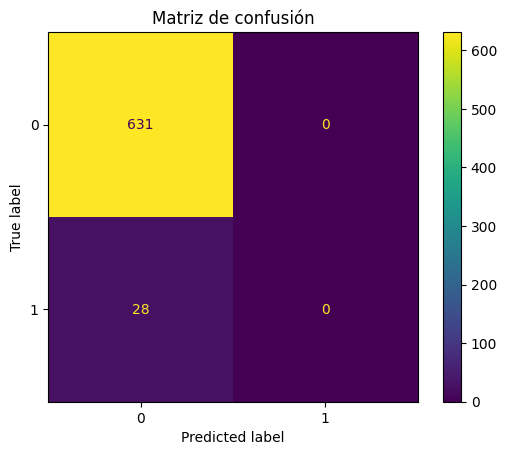

In [19]:
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.metrics import accuracy_score

dummy_acc = DummyClassifier(strategy='most_frequent', random_state=7)
dummy_acc.fit(Xtrain, ytrain)
y_pred = dummy_acc.predict(Xtrain)
print("Accuracy:", accuracy_score(ytrain, y_pred))

ConfusionMatrixDisplay.from_predictions(ytrain, y_pred, labels=[0,1])

plt.title("Matriz de confusión")
plt.show()


# **Ejercicio-4**

* ### **Ya que tenemos las referencias de los modelos base (baseline) o ingenuo (naive) para las métricas de exactitud (accuracy) y G-mean. Ejecuta a continuación la siguiente celda. Observa que estaremos ejecutando los modelos con el mínimo de ajuste de los valores predeterminados de los hiperparámetros. Esto con el objetivo de tener un punto de partida sobre qué tan alejados estamos de obtener buenos modelos. Sirve también como ejemplo para mostrar cómo se  desempeñan los modelos cuando se ejecutan con sus valores predeterminados, que en muchas ocasiones son los resultados que muestran algunos LLM (modelos grandes de lenguaje). Esto nos muestra que no porque no tengamos errores de ejecución o compilación, no significa que ya alcanzamos el objetivo buscado.**

* ### **Observa que estamos usando los conjuntos Xtv y ytv para entrenar los modelos ya que estamos utilizando validación cruzada y además, mostramos al inicio que tenemos muy pocos datos de la clase positiva minoritaria en el conjunto de validación.**

Resultados de Validación:
LR
Exactitud: >> 0.947 (0.015)
G-mean: >> 0.654 (0.119)

LASSO
Exactitud: >> 0.960 (0.009)
G-mean: >> 0.501 (0.158)

RIDGE
Exactitud: >> 0.959 (0.008)
G-mean: >> 0.541 (0.113)

EN
Exactitud: >> 0.960 (0.007)
G-mean: >> 0.540 (0.109)

kNN
Exactitud: >> 0.956 (0.006)
G-mean: >> 0.174 (0.187)



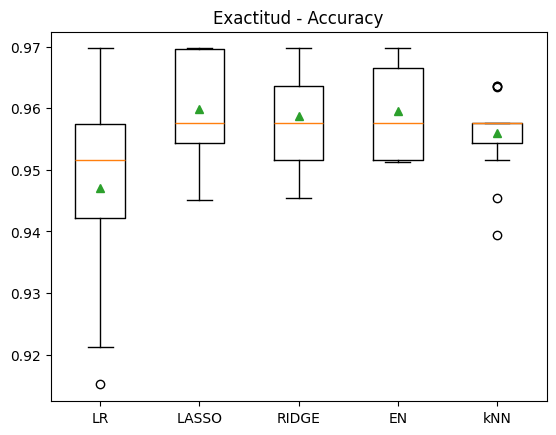

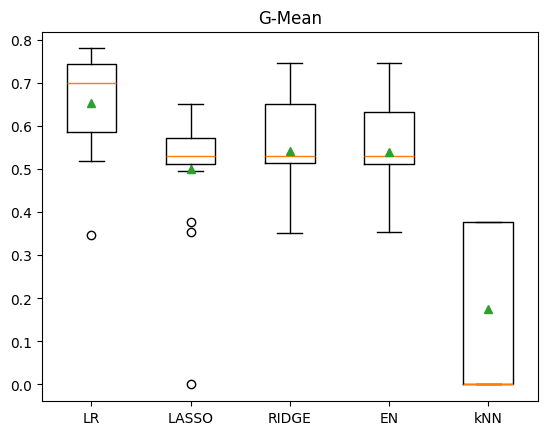

In [32]:
# Código-1:

# Ejecuta esta celda sin modificaciones.

# Estamos ejecutando los modelos con el mínimo de ajustes para usar sus valores predetermiandos
# y mostrando los desempeños con las métricas de exactitud (accuracy) y G-mean.

# Definimos primeramente los modelos a entrenar y evaluar:

from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_validate

def mis_modelos1():
  modelos, nombres = list(), list()

  modelos.append(LogisticRegression(penalty=None, # Este valor del argumento define el modelo sin regularización.
                                    max_iter=2000,
                                    random_state=1))
  nombres.append('LR')


  modelos.append(LogisticRegression(penalty='l1',  # modelo Lasso o de métrica L1.
                                    solver='liblinear',
                                    max_iter=2000,
                                    random_state=1))
  nombres.append('LASSO')


  modelos.append(LogisticRegression(penalty='l2',   # modelo Ridge o de métrica L2.
                                    max_iter=2000,
                                    random_state=1))
  nombres.append('RIDGE')

  modelos.append(LogisticRegression(penalty='elasticnet',  # modelo Elastic-Net o de métrica L1-L2.
                                    l1_ratio=0.5,
                                    solver='saga',
                                    max_iter=5000,
                                    random_state=1))
  nombres.append('EN')

  modelos.append(KNeighborsClassifier(n_neighbors=5))
  nombres.append('kNN')

  return modelos, nombres

# +++++++++++++++++++++++++++++++++++++++++++++++++++++++++


modelos, nombres = mis_modelos1()
resultados1, resultados2 = list(), list()
print('Resultados de Validación:')

for i in range(len(modelos)):

  pipeline = Pipeline(steps=[('ct',columnasTransformer),('m',modelos[i])])
  cv1 = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=7)
  scores = cross_validate(pipeline,
                          Xtv,
                          np.ravel(ytv),
                          scoring={'exactitud':'accuracy', 'm_geo':mi_metrica},
                          cv=cv1)

  resultados1.append(scores['test_exactitud'])
  resultados2.append(scores['test_m_geo'])

  print(nombres[i])
  print('Exactitud: >> %.3f (%.3f)' % (np.nanmean(scores['test_exactitud']), np.nanstd(scores['test_exactitud'])))
  print('G-mean: >> %.3f (%.3f)' % (np.nanmean(scores['test_m_geo']), np.nanstd(scores['test_m_geo'])))
  print()

plt.boxplot(resultados1, tick_labels=nombres,  showmeans=True)
plt.title("Exactitud - Accuracy")
plt.show()

plt.boxplot(resultados2, tick_labels=nombres,  showmeans=True)
plt.title("G-Mean")
plt.show()

### **Habiendo ejecutado la celda anterior sin ajustar hiperparámetros, responde lo siguiente:**

### **4a) ¿Cuáles modelos están subentrenados con respecto a la métrica de la exactitud (accuracy)?**

### **4b) ¿Cuáles modelos están subentrenados con respecto a la métrica de la media geométrica (G-mean)?**


### +++++++++++ Inicia sección para agregar texto ++++++++++++++++


* 4a) Los modelos subentrenados según "Accuracy" son: LR con un "Accuracy" = 94.7% & KNN con un "Accuracy" = 95.6%

Me parece importante mencionar que aunque LR está subentrenado segpun "Accuracy", cuenta con un "g-mean" alto, lo que nos puede decir que realmente tiene un mejor equilibrio entre la detección de derrames y no derrames.

* 4b) Los modelos subentrenados según "G-mean" son: Lasso con un "G-mean" = 50.1% & kNN con un "G-mean" = 17.4%


### +++++++++++ Termina sección para agregar texto ++++++++++++++

# **Ejercicio-5**

* ### **Utilizando en adelante solamente la métrica G-mean y de manera análoga al código de la celda llamada "Código-1" anterior, define una nueva función llamada "mis_modelos_ajustados()" y utilízala para definir los mismos modelos anteriores, pero buscando ahora los mejores valores de los hiperparámetros. Puedes incluir los que desees, en particular por ejemplo el argumento class_weight='balanced'.**

* ### **La salida no deberá mostrar errores o advertencias (warnings).**

* ### **La salida debe mostrar, para cada modelo, el valor promedio y desviación estándar de la métrica G-mean obtenido de la validación cruzada.**

* ### **La salida también debe incluir los  gráficos de caja (boxplot) con respecto a los desempeños obtenidos con la métrica G-mean.**


* ### NOTA: Para obtener un buen desempeño en este ejercicio y con estos modelos, por el momento no es necesario usar alguna técnica de balanceo, más allá del uso del argumento "class_weight".

Resultados de los modelos ajustados con la métrica G-mean
++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++
Resultados de Validación:
LR
Exactitud: >> 0.914 (0.019)
G-mean: >> 0.754 (0.120)

LASSO
Exactitud: >> 0.877 (0.027)
G-mean: >> 0.804 (0.081)

RIDGE
Exactitud: >> 0.882 (0.023)
G-mean: >> 0.801 (0.083)

EN
Exactitud: >> 0.878 (0.025)
G-mean: >> 0.799 (0.083)

kNN
Exactitud: >> 0.956 (0.006)
G-mean: >> 0.174 (0.187)



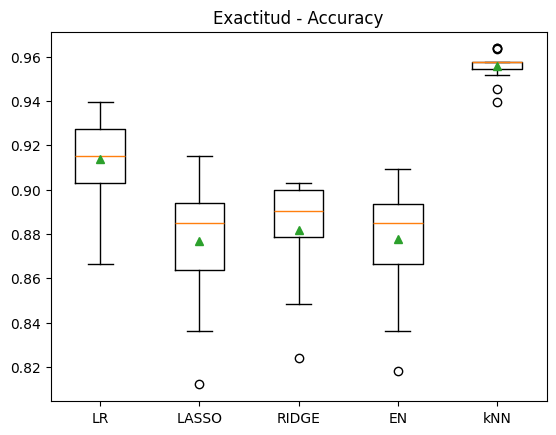

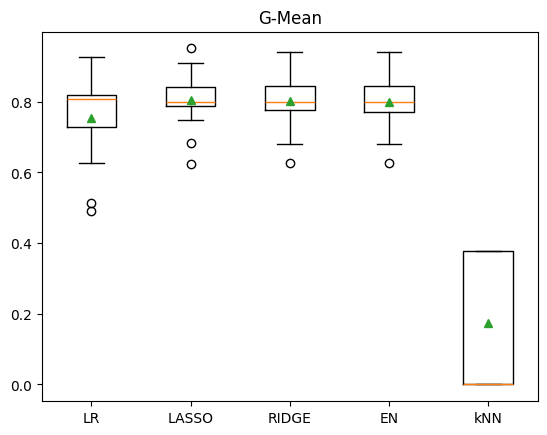

In [24]:
# 5)



print('Resultados de los modelos ajustados con la métrica G-mean')
print('+'*80)

# ++++++++++ Inicia sección para agregar tu código ++++++++++++++++++++++++
# NOTA: puedes agregar todas las celdas que consideres adecuado.

from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_validate

def mis_modelos_ajustados():
  modelos, nombres = list(), list()

  modelos.append(LogisticRegression(penalty=None, # Este valor del argumento define el modelo sin regularización.
                                    max_iter=2000,
                                    class_weight='balanced',
                                    random_state=1))
  nombres.append('LR')


  modelos.append(LogisticRegression(penalty='l1',  # modelo Lasso o de métrica L1.
                                    solver='liblinear',
                                    class_weight='balanced',
                                    max_iter=2000,
                                    random_state=1))
  nombres.append('LASSO')


  modelos.append(LogisticRegression(penalty='l2',                                  # modelo Ridge o de métrica L2.
                                    class_weight='balanced',
                                    max_iter=2000,
                                    random_state=1))
  nombres.append('RIDGE')

  modelos.append(LogisticRegression(penalty='elasticnet',  # modelo Elastic-Net o de métrica L1-L2.
                                    l1_ratio=0.5,
                                    solver='saga',
                                    class_weight='balanced',
                                    max_iter=5000,
                                    random_state=1))
  nombres.append('EN')

  modelos.append(KNeighborsClassifier(n_neighbors=5))
  nombres.append('kNN')

  return modelos, nombres

# +++++++++++++++++++++++++++++++++++++++++++++++++++++++++


modelos, nombres = mis_modelos_ajustados()
resultados1, resultados2 = list(), list()
print('Resultados de Validación:')

for i in range(len(modelos)):

  pipeline = Pipeline(steps=[('ct',columnasTransformer),('m',modelos[i])])
  cv1 = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=7)
  scores = cross_validate(pipeline,
                          Xtv,
                          np.ravel(ytv),
                          scoring={'exactitud':'accuracy', 'm_geo':mi_metrica},
                          cv=cv1)

  resultados1.append(scores['test_exactitud'])
  resultados2.append(scores['test_m_geo'])

  print(nombres[i])
  print('Exactitud: >> %.3f (%.3f)' % (np.nanmean(scores['test_exactitud']), np.nanstd(scores['test_exactitud'])))
  print('G-mean: >> %.3f (%.3f)' % (np.nanmean(scores['test_m_geo']), np.nanstd(scores['test_m_geo'])))
  print()

plt.boxplot(resultados1, tick_labels=nombres,  showmeans=True)
plt.title("Exactitud - Accuracy")
plt.show()

plt.boxplot(resultados2, tick_labels=nombres,  showmeans=True)
plt.title("G-Mean")
plt.show()



# ++++++++++ Termina sección para agregar tu código ++++++++++++++++++++++++


# **Ejercicio-6**

### **a) Selecciona el que consideres sea el mejor modelo encontrado, busca la mejor configuración de hiperparámetros y utilízalo para encontrar su matriz de confusión. Lamarlo "mejor_modelo". Sigue utilizando los mismos conjuntos de entrenamiento y validación. Llamar "ytrain_hat" y "yval_hat" a las predicciones de los conjuntos de entrenamiento y validación, respectivamente, obtenidas con el mejor modelo. Verifica ahora que tampoco quede sobreentrenado, considerando que la diferencia entre entrenamiento y validación no sea mayor al $3\%$. Utilizar random_state=1 en el modelo seleccionado.**

### **b) Observa que estamos también mostrando los valores de la exactitud de este mejor modelo. ¿Cómo justificas que el valor de la exactitud es menor que el obtenido anteriormente? Compara con la salida de la celda llamada "Código-1".**

###  **c) Con el mejor modelo y el conjunto de validación, obtener el gráfico de la curva-ROC, donde se incluya el valor del área bajo la curva AUC del mejor modelo y también el AUC del modelo que predice siempre la clase positiva (chance level). Ver documentación.**

###  **d) Con el mejor modelo y el conjunto de validación, obtener el gráfico de la curva-PR, donde se incluya el valor del área bajo la curva AUC del mejor modelo y también el AUC del modelo que siempre predice la clase positiva (chance level). Ver documentación.**

### **e) Con base a los resultados de los gráficos ROC y PR incluye tus conclusiones en el contexto del problema.**




In [26]:
# Respuesta Ejercicio-6a:

# **+++++++++++ Inicia sección para agregar código ++++++++++++++++**

# NOTA: puedes agregar todas las celdas que consideres adecuado.


None

mejor_modelo = Pipeline(steps=[
        ('ct',columnasTransformer),
        ('m',LogisticRegression(
            penalty='l1',
            solver='liblinear',
            class_weight='balanced',
            C=1.0,
            max_iter=2000,
            random_state=1))
])

mejor_modelo.fit(Xtrain, np.ravel(ytrain))
ytrain_hat = mejor_modelo.predict(Xtrain)

yval_hat = mejor_modelo.predict(Xval)

None



# **+++++++++++ Termina sección para agregar código ++++++++++++++**

print('G-mean del mejor modelo-Train: %.4f' % geometric_mean_score(np.ravel(ytrain), ytrain_hat))
print('G-mean del mejor modelo-Val: %.4f' % geometric_mean_score(np.ravel(yval), yval_hat))

print('\nExactitud del mejor modelo-Train: %.4f' % accuracy_score(np.ravel(ytrain), ytrain_hat))
print('Exactitud del mejor modelo-Val: %.4f' % accuracy_score(np.ravel(yval), yval_hat))

print("\nMatriz de Confusión con Validación:\n", confusion_matrix(np.ravel(yval), yval_hat))

print("\nMatriz de Confusión en porcentajes y con Validación:\n", confusion_matrix(np.ravel(yval), yval_hat, normalize='all'))

G-mean del mejor modelo-Train: 0.9267
G-mean del mejor modelo-Val: 0.9443

Exactitud del mejor modelo-Train: 0.8938
Exactitud del mejor modelo-Val: 0.8970

Matriz de Confusión con Validación:
 [[140  17]
 [  0   8]]

Matriz de Confusión en porcentajes y con Validación:
 [[0.84848485 0.1030303 ]
 [0.         0.04848485]]


El modelo elegido como mejor modelo es: LASSO, con un G-mean = 80.4 % y una desviación estándar de 0.081
Podemos visualizar que el modelo no está sobre enrenado ya que la diferencia entre XTrain & XVal es = 1.7%
La matriz de confusión de validación nos muestra que el modelo identificó correctamente los 8 derrames reales aunque aun generó 17 falsos positivos.

Respuesta Ejercicio-6b:

### +++++++++++ Inicia sección para agregar texto ++++++++++++++++


* 6b) El accuracy está disminuyendo porque el modelo está dando mayor importancia a identificar derrames al usar class_weight='balanced'. Lo cual considero aceptable, ya que el modelo prioriza la detección de derrames reales, aunque pueda tener más falsos positivos. Las consecuencias de no detectar oportundamente un derramente podrían generar un mayor impacto.


### +++++++++++ Termina sección para agregar texto ++++++++++++++

AUC-ROC: 0.9729


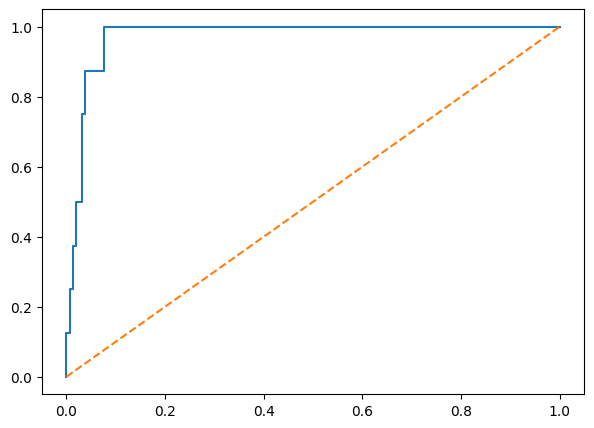

In [28]:
# Respuesta Ejercicio-6c:

# **+++++++++++ Inicia sección para agregar código ++++++++++++++**

from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

yval_prob = mejor_modelo.predict_proba(Xval)[:,1]
fpr, tpr, thresholds = roc_curve(yval, yval_prob)
auc_roc = roc_auc_score(yval, yval_prob)

plt.figure(figsize=(7,5))
plt.plot(fpr, tpr, label=f'Mejor modelo (AUC = {auc_roc:.2f})')
plt.plot([0, 1], [0, 1], '--', label='Chance level (AUC = 0.5)')
print(f"AUC-ROC: {auc_roc:.4f}")



# **+++++++++++ Termina sección para agregar código ++++++++++++++**

La curva ROC muestra que el modelo presenta una buena capacidad para distinguir entre observaciones con y sin derrame, ya que se encuentra por encima de la línea de referencia y se aproxima a la esquina izquierda.

El valor AUC = 0.9729, lo cual nos indica que la interpretación de la gráfica es correcta, ya que nos indica una excelente capacidad para distinguir las observaciones con y sin derrame.

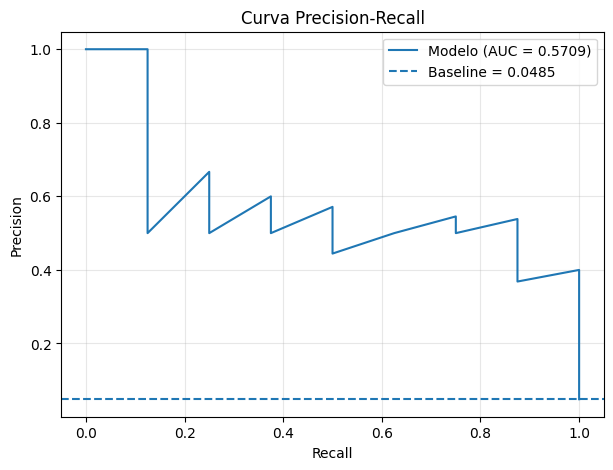

AUC Precision-Recall: 0.5709


In [30]:
# Respuesta Ejercicio 6d:

# **+++++++++++ Inicia sección para agregar código ++++++++++++++**


from sklearn.metrics import precision_recall_curve, auc
import matplotlib.pyplot as plt

precision, recall, thresholds = precision_recall_curve(
    yval, yval_prob
)

auc_pr = auc(recall, precision)

plt.figure(figsize=(7, 5))
plt.plot(recall, precision, label=f'Modelo (AUC = {auc_pr:.4f})')

baseline_pr = sum(yval == 1) / len(yval)
plt.axhline(
    baseline_pr,
    linestyle='--',
    label=f'Baseline = {baseline_pr:.4f}'
)

plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Curva Precision-Recall')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print(f'AUC Precision-Recall: {auc_pr:.4f}')



# **+++++++++++ Termina sección para agregar código ++++++++++++++**

Respuesta Ejercicio-6e:

### +++++++++++ Inicia sección para agregar texto ++++++++++++++++

* 6e) Observamos que el valor AUC PRecision-Recall = 0.5709 es bajo porque, aunque el modelo está identificando correctamente los derrames, también está generando falsos positivos.
Considero que el modelo es aceptable al contar con AUC-ROC fuerte, ya que considero que ejercicio se enfoca en poder determinar correctamente los derrames.


### +++++++++++ Termina sección para agregar texto ++++++++++++++

In [33]:
# Mostremos finalmente el siguiente resumen con varias métricas:
from imblearn.metrics import classification_report_imbalanced

print(classification_report_imbalanced(np.ravel(yval), yval_hat,
                                       target_names=['class 0:non-spill', 'class 1:oil-spill']))

                         pre       rec       spe        f1       geo       iba       sup

class 0:non-spill       1.00      0.89      1.00      0.94      0.94      0.88       157
class 1:oil-spill       0.32      1.00      0.89      0.48      0.94      0.90         8

      avg / total       0.97      0.90      0.99      0.92      0.94      0.88       165



# **Ejercicio-7**

En los ejercicios previos ya lograste entrenar un buen modelo utilizando la métrica G-mean. Sin embargo, sabemos que en la industria un modelo no se despliega solamente porque tiene buenas métricas estadísticas, se despliega para resolver un problema de negocio. Introduzcamos a continuación información en esta dirección.

En los ejercicios anteriores el umbral de decisión por defecto del modelo logístico (independientemente de si usamos L1, L2 o ElasticNet) fue 0.5. Con este valor de decisión de 0.5 y del reporte de métricas de la celda anterior, observamos que aproximadamente el modelo detecta el 100% de los derrames (Recall ≈ 1.0), pero a costa de generar muchas falsas alarmas (Precisión ≈ 0.32).

Sabemos que el umbral de decisión predeterminado de 0.5 de los modelos logísticos es una convención arbitraria. Como ingenieros de IA, deberán ajustar ahora este umbral tomando en cuenta el costo de de cada nuno de los errores.

* **El Escenario de Negocio es el siguiente: Imagina que estás desplegando este modelo para la Guardia Costera y la Agencia de Protección Ambiental y te proporcionan la siguiente información:**

   * **Costo de un Falso Negativo (FN):** Cuando el modelo predice erróneamente que el "océano está limpio" y que no hay derrame de combustible, el costo es de $1,000,000 USD. El costo considera multas, limpieza de emergencia, daño ecológico, técnicos especialistas, disminución de tu reputación, etc.

   * **Costo de un Falso Positivo (FP):** Cuando el modelo predice erróneamente que "sí hay derrame", el costo es de $15,000 USD. Puede ser la detección de los llamados casos "look-alike", como las manchas de algas, entre otros. El costo considera el uso y combustible de un helicóptero para inspeccionar, horas hombre, entre otros.

   * El costo de error de los **casos Verdaderos (TP y TN)** es de $0 USD.

* **7a) Con base a esta información y tu mejor modelo encontrado previamente, utiliza un modelo de lenguaje de gran tamaño, LLM, para que te ayude a escribir una función en Python que calcule el "Costo Total Esperado" del problema, iterando a través de diferentes umbrales de probabilidad (desde 0.1 hasta 0.9). Utiliza solamente el conjunto de validación.**

* **7b) Incluye además una gráfica del Costo Total Esperado (eje Y)contre el valor de umbral (eje X). Despliega e indica visualmente dicho valor del umbral óptimo obtenido y su valor del costo total asociado.**

* **7c) A modo de comparación, muestra la matriz de confusión (en valores brutos) y el valor de la métrica G-mean para el caso del umbral de decisión predeterminado 0.5 y el del mejor umbral obtenido en los incisos anteriores.**

* **7d) ¿Cómo cambia la estrategia de despliegue respecto al umbral original predeterminado de 0.5? En particular, ¿consideras que vale la pena cambiarlo?**

* **7e) Indica el LLM utilizado e incluye el prompt o prompts que usaste en los incisos 7a y 7b anteriores.**





In [34]:
# Respuesta Ejercicio 7:

# +++++++ Incluye a continuación todos las celdas de texto y código que consideres adecuadas.

import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix

# Costos en USD
costo_FN = 1_000_000
costo_FP = 15_000

# Probabilidades del conjunto de validación
y_prob = mejor_modelo.predict_proba(Xval)[:, 1]

# Evaluar umbrales de 0.10 a 0.90
umbrales = np.round(np.arange(0.10, 0.91, 0.01), 2)

resultados = []

for umbral in umbrales:

    # Clasificación según el umbral
    y_pred = (y_prob >= umbral).astype(int)

    # Matriz de confusión
    tn, fp, fn, tp = confusion_matrix(
        yval, y_pred, labels=[0, 1]
    ).ravel()

    # Costo total
    costo_total = (fn * costo_FN) + (fp * costo_FP)

    resultados.append({
        'Umbral': umbral,
        'FP': fp,
        'FN': fn,
        'Costo Total': costo_total
    })

df_costos = pd.DataFrame(resultados)

# Identificar el umbral con menor costo
mejor_resultado = df_costos.loc[
    df_costos['Costo Total'].idxmin()
]

print("Umbral óptimo:", mejor_resultado['Umbral'])
print("Costo mínimo: $", f"{mejor_resultado['Costo Total']:,.0f}")
print("Falsos positivos:", int(mejor_resultado['FP']))
print("Falsos negativos:", int(mejor_resultado['FN']))


Umbral óptimo: 0.66
Costo mínimo: $ 180,000
Falsos positivos: 12
Falsos negativos: 0


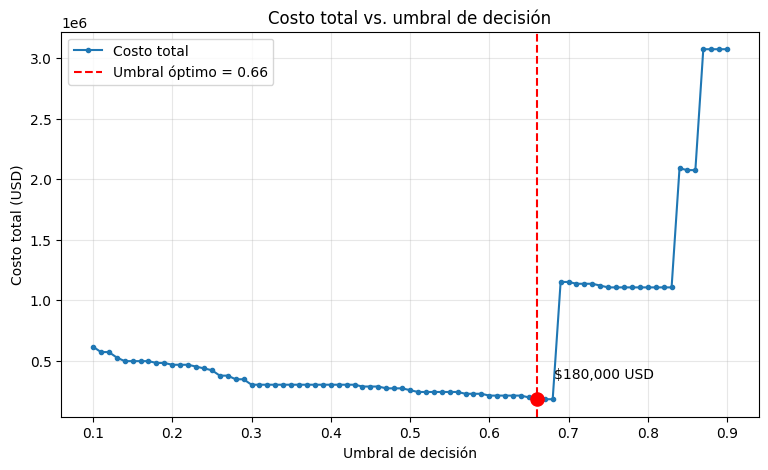

In [35]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.plot(
    df_costos['Umbral'],
    df_costos['Costo Total'],
    marker='.',
    label='Costo total'
)

plt.axvline(
    mejor_resultado['Umbral'],
    color='red',
    linestyle='--',
    label=f"Umbral óptimo = {mejor_resultado['Umbral']:.2f}"
)

plt.scatter(
    mejor_resultado['Umbral'],
    mejor_resultado['Costo Total'],
    color='red',
    s=90,
    zorder=5
)

plt.annotate(
    f"${mejor_resultado['Costo Total']:,.0f} USD",
    (
        mejor_resultado['Umbral'],
        mejor_resultado['Costo Total']
    ),
    xytext=(12, 15),
    textcoords='offset points'
)

plt.xlabel('Umbral de decisión')
plt.ylabel('Costo total (USD)')
plt.title('Costo total vs. umbral de decisión')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

El LLM me explica que desarrolló una función en Python para evaluar el costo total de clasificación utilizando diferentes umbrales de decisión, desde 0.10 hasta 0.90, considerando un costo de $1,000,000 USD por falso negativo y $15,000 USD por falso positivo.

A partir de los resultados obtenidos con el conjunto de validación, se identificó un umbral óptimo de 0.66, con un costo total de $180,000 USD, correspondiente a 12 falsos positivos y ningún falso negativo.

En comparación con el umbral predeterminado de 0.50, cuyo costo era de $255,000 USD, se obtuvo una reducción de $75,000 USD, equivalente al 29.4%.

La gráfica muestra que aumentar el umbral permite reducir los costos asociados a falsas alarmas. Sin embargo, al superar cierto valor, el costo aumenta considerablemente debido a la aparición de falsos negativos, cuyo impacto económico es significativamente mayor.

Por lo tanto, el umbral de 0.66 representa la mejor alternativa entre los valores evaluados, al minimizar el costo observado sin comprometer la detección de derrames reales en el conjunto de validación.

In [36]:
from imblearn.metrics import geometric_mean_score

for umbral in [0.50, 0.66]:

    y_pred = (y_prob >= umbral).astype(int)

    matriz = confusion_matrix(yval, y_pred, labels=[0, 1])
    gmean = geometric_mean_score(yval, y_pred)

    print(f"\nUmbral: {umbral}")
    print("Matriz de confusión:")
    print(matriz)
    print(f"G-mean: {gmean:.4f}")


Umbral: 0.5
Matriz de confusión:
[[140  17]
 [  0   8]]
G-mean: 0.9443

Umbral: 0.66
Matriz de confusión:
[[145  12]
 [  0   8]]
G-mean: 0.9610


7d) Sí considero que vale la pena cambiarlo porque incluso se aumentó el G-mean, y por supuesto, como lo vimos en la respuesta, se están disminuyendo los Falsos Positivos sin impactar en la detección de derrames reales.
Por lo que se está disminuyendo en el costo general.

7e) LLM utilizado: ChatGPT, modelo GPT-6, desarrollado por OpenAI.

Prompt 1 — Ejercicio 7a:

Ayúdame a desarrollar una función en Python para evaluar el costo total de clasificación utilizando mi mejor modelo de regresión logística LASSO, previamente entrenado y almacenado en la variable mejor_modelo.

Utiliza directamente mejor_modelo, sin crear ni entrenar un nuevo modelo, y considera únicamente el conjunto de validación (Xval, yval).

El costo de un falso negativo es de $1,000,000  USD y el de un falso positivo es de $15,000 USD. Los verdaderos positivos y verdaderos negativos tienen costo cero.

Necesito evaluar diferentes umbrales de decisión desde 0.10 hasta 0.90, utilizando las probabilidades obtenidas mediante mejor_modelo.predict_proba(Xval).

Para cada umbral, calcula los falsos positivos, falsos negativos y el costo total de clasificación. Finalmente, identifica el umbral que minimiza el costo total y muestra los resultados.

Prompt 2 — Ejercicio 7b:

A partir de los resultados obtenidos utilizando mejor_modelo y el conjunto de validación, ayúdame a generar una gráfica en Python utilizando Matplotlib.

La gráfica debe mostrar el costo total de clasificación en USD (eje Y) y los diferentes umbrales de decisión evaluados desde 0.10 hasta 0.90 (eje X).

Incluye una línea vertical que identifique el umbral óptimo y una anotación que muestre el costo mínimo asociado.

Reutiliza los resultados calculados anteriormente, sin volver a entrenar el modelo.

# **Ejercicio-8**

**Has completado el ciclo de desarrollo y análisis del modelo de detección de derrames. Considera que tenemos el problema de derramamiento de combustible anterior y todo el análisis que has realizado hasta ahora. A continuación, deberás hacer un reporte para "vender tu solución". Para ello, considera el siguiente escenario:**

* **Supongamos que eres el ingeniero líder de IA de la Guarda Costera. A tu Director de Operaciones (que no conoce de tecnicismos de IA o Estadística) le hicieron llegar un reporte generado automáticamente por una herramienta de Inteligencia de Negocio (BI, por sus siglas en inglés). La conclusión de dicho reporte dice lo siguiente:**

     * **"El modelo tiene una Exactitud (Accuracy) del 96%. ¡Es casi perfecto! Propongo despedir a los 3 analistas humanos y dejar que el modelo envíe automáticamente los helicópteros de inspección cada vez que detecte algo".**


* **Tú sabes que esta conclusión es peligrosa e incorrecta tan solo por el alto desbalanceo de clases, pero además porque ya tienes los resultados analíticos anteriores de esta actividad que te pueden ayudar a soportar mejores decisiones y refutar la conlusión del reporte de la herramienta de BI.**

* **Redacta un reporte ejecutivo de máximo 1 página (400 palabras aproximadamente) dirigido al Director de Operaciones y con las siguientes características:**
   * **El reporte no debe estar lleno te fórmulas o métricas. En dado caso, si decides mencionar explícitamente por ejemplo "G-mean" o "curva ROC", deberás primero explicarlas.**
   
   * **El reporte debe incluir una explicación de las implicaciones de cometer errores de FP o FN con el modelo ingenuo, en comparación con los resultados de tu mejor modelo. La explicación debe ser nuevamente en el contexto del problema y sin tecnicismos.**

   * **Propón un plan de despliegue concreto del modelo que justifique y ayude a mantener a los 2 analistas humanos en sus puestos de trabajo. NOTA: Puedes revisar y aporate en el concepto conocido en inglés como "Human-in-the-loop" en IA.**







Respuesta Ejercicio-8):

### +++++++++++ Inicia sección para agregar texto ++++++++++++++++

**Dirigido a:** Director de Operaciones de la Guardia Costera

**Asunto:** Evaluación del modelo, impacto económico y estrategia de implementación

La implementación de Inteligencia Artificial para detectar derrames de combustible representa una oportunidad para optimizar recursos, reducir tiempos de respuesta y prevenir daños ambientales. Sin embargo, considero que su implementación debe sustentarse en resultados operativos y económicos, manteniendo la supervisión humana como parte indispensable del proceso.

**Evaluación del modelo**

Aunque el reporte inicial indica una exactitud del 96%, este resultado no garantiza que el modelo identifique correctamente los derrames. Aproximadamente el 96% de los registros corresponden a casos sin derrame, por lo que un modelo podría alcanzar esa exactitud sin detectar un solo incidente real.

Además, las condiciones ambientales, las características de los derrames y las variaciones en los datos pueden modificar el desempeño del modelo. Por ello, es indispensable que especialistas supervisen sus resultados, identifiquen posibles errores y tomen decisiones considerando información adicional.

**Impacto económico y optimización**

Los errores de clasificación tienen consecuencias diferentes. No detectar un derrame representa un costo estimado de $1,000,000 USD, mientras que una falsa alarma implica aproximadamente $15,000 USD en recursos de inspección.

Durante el análisis observamos que los modelos con mayor exactitud no necesariamente identificaban adecuadamente los derrames. Al priorizar su detección, conseguimos mejorar los resultados, aunque inicialmente se generaron falsas alarmas que también representaban costos operativos.

Posteriormente, al optimizar el umbral de decisión, logramos reducir las falsas alarmas de 17 a 12, manteniendo la detección de los ocho derrames reales del conjunto de validación. Esto representó una reducción del costo estimado de $255,000 a $180,000 USD, equivalente al 29.4%.

**Estrategia de implementación y supervisión humana**

Propongo implementar un sistema de apoyo a las decisiones bajo el enfoque Human-in-the-loop, donde la IA realice el análisis inicial y los especialistas validen sus resultados antes de autorizar acciones operativas.

Dos analistas podrían encargarse de revisar alertas, contrastarlas con información ambiental y determinar la necesidad de inspecciones. Un tercer analista podría supervisar el desempeño del modelo, investigar errores y proponer mejoras continuas.

Su conocimiento es indispensable para identificar condiciones no contempladas durante el entrenamiento, cuestionar las predicciones y retroalimentar el sistema, evitando que las decisiones dependan exclusivamente de resultados automatizados.

**Conclusión**

Recomiendo implementar inicialmente un programa piloto supervisado, conservando al personal especializado y evaluando continuamente los resultados.

El objetivo no debe ser sustituir el criterio humano, sino aprovechar la IA para automatizar actividades repetitivas y permitir que los especialistas se concentren en decisiones de mayor valor, reduciendo riesgos ambientales y costos operativos.


### +++++++++++ Termina sección para agregar texto ++++++++++++++

# **Ejercicio-9**

### **Incluye tus conclusiones finales.**


### +++++++++++ Inicia sección de Conclusiones ++++++++++++++++

Lo más importante a destacar al usar datos con clases no balanceadas es que la gran disparidad de las clases nos puede llevar a tener un modelo con accuracy alto que aparentemente represente el buen desarrollo del modelo, sin embargo es importante entender que no precisamente es así. Este mismo accuracy puede llevarnos a que el modelo no detecte correctamente valores objetivo en el ejercicio y que representen un impacto negativo en el negocio.
Es importante trabajar con métricas que nos ayuden a entender de mejor manera el comportamiento de los datos para generar modelos adecuados al enfoque que estamos buscando.
El G-mean es una buena forma de entender el comportamienro del modelo a través de otras métricas funcionales como el recall y el sensibility.


### +++++++++++ Termina sección de conclusiones ++++++++++++++

# **<<< Fin de la Actividad de la Semana - Clases Desbalanceadas - Oil-Spill >>>**